# T41 — True polar wander from two reference frames

**Cluster F: Paleomagnetism.**

A plate reconstruction can be expressed in two different reference frames: a **mantle frame** (continents are moved relative to the deep mantle, for example via hotspot or LLSVP constraints) and a **paleomagnetic frame** (continents are moved so that their paleolatitudes agree with the paleomagnetic record, i.e. relative to the spin axis). Whenever the whole solid Earth rotates relative to the spin axis, the two frames drift apart. That whole-Earth rotation is **true polar wander (TPW)**.

**Where this notebook sits in the paper's story.** T35 (paleo-mantle reference-frame uncertainty) shows that the Zahirovic 2022 mantle frame and paleomagnetic frame put continents in *different* positions at the same age. T68 (Leonard 2025) shows the downstream consequence for reconstructed climate. **This notebook explains why**: the difference between the two frames is the accumulated TPW.

## What this notebook produces

TPW is computed here the way an *apparent polar wander path* (APWP) is computed, with the **mantle as the anchored plate** (the approach of Vaes & van Hinsbergen 2025): the track of the spin axis in mantle coordinates. This gives a TPW path with a well-defined direction, and TPW rates that cannot change sign.

1. **§3, TPW path.** At each age from 0 to `MAX_AGE_MA` in `STEP_MA` steps, the rotation between the mantle frame (anchor 0) and the paleomagnetic frame (anchor 701701) is used to find where the present-day north pole sits in mantle coordinates. The path starts at 90°N at 0 Ma. The accumulated TPW at each age is a rotation about an **equatorial** axis (any rotation component about the spin axis itself is a longitude shift that paleomagnetism cannot constrain, and is not TPW).
2. **§4, TPW rate.** The great-circle distance between consecutive points of the path, divided by the time step, in ° per Myr (always ≥ 0).
3. **§5, TPW path on a polar map**, coloured by age.
4. **§6, rate through time** as a bar chart.
5. **§7, a second paleomagnetic frame** (the GPMDB-based anchor 701702 built in T33) for comparison with the built-in 701701 frame.

## Learning objectives

- Combine `pygplates.RotationModel` calls with different `anchor_plate_id` values to isolate the rotation between a mantle frame and a paleomagnetic frame.
- Express TPW as the path of the spin axis in mantle coordinates (an APWP of the mantle) and as accumulated rotations about equatorial axes.
- Compute TPW rates as non-negative great-circle distances per unit time, and understand why the sign of a rotation angle returned by `get_euler_pole_and_angle()` must not be used as a rate.
- Compare the TPW implied by two different paleomagnetic frames.

## Prerequisites and runtime

- Plate model: Zahirovic 2022 (via `plate_model_manager`). §7 additionally needs the augmented rotation file produced by T33 (`data/Zahirovic2022_with_gpmdb_frame.rot`); if it is missing, §7 is skipped with a message.
- No published TPW curve is hard-coded. To benchmark the results, add values digitised or downloaded from the original publications (see *Extend this*).
- Python: `gplately`, `pygplates`, `pygmt`, `pandas`, `numpy`.
- Runtime: a few seconds (rotation arithmetic only; two to four pyGMT figures).


## Environment + imports


In [1]:
from pathlib import Path
import os, sys
if Path("../data").exists() and not Path("data").exists():
    os.chdir("..")

import numpy as np
import pandas as pd
import pygmt
import gplately
import pygplates
from plate_model_manager import PlateModelManager
import sys as _sys
from pathlib import Path as _P
for _d in (_P("Notebooks"), _P("."), _P("../Notebooks")):
    if (_d / "pmm_local.py").exists():
        _sys.path.insert(0, str(_d.resolve())); break
from pmm_local import LocalFirstPMM   # uses the local cache if the model server is unreachable

print("Environment")
print(f"  python      {sys.version.split()[0]}")
for _m in (np, pd, pygmt, gplately, pygplates):
    print(f"  {_m.__name__:11s} {getattr(_m, '__version__', 'n/a')}")


Environment
  python      3.12.5
  numpy       2.3.2
  pandas      3.0.6
  pygmt       v0.19.0
  gplately    2.0.0.post19+git.2cce7bb3
  pygplates   1.0.0


In [2]:
# === USER CONFIGURATION =====================================================
MODEL_NAME               = "Zahirovic2022"

# The plate used to compare the two frames. Africa is the canonical choice
# because the Z22 paleomagnetic frame is anchored on it (701 → 701701).
# The two-frame rotation is the same for every plate, so any plate that is
# connected to both anchors gives the same answer.
PLATE_ID_MANTLE_FRAME    = 701          # Africa in Z22 default (mantle) frame
PLATE_ID_PALEOMAG_FRAME  = 701          # Africa in the paleomag-anchor chain
ANCHOR_MANTLE_FRAME      = 0            # Z22 default mantle anchor
ANCHOR_PALEOMAG_FRAME    = 701701       # Z22 synthetic paleomag anchor for Africa

# Time discretisation
MAX_AGE_MA               = 400          # cap at Z22's ~410 Ma coverage
STEP_MA                  = 5            # 5-Myr cadence
AGES                     = np.arange(0, MAX_AGE_MA + STEP_MA, STEP_MA)

# TPW-path map settings
POLE_PATH_REGION         = [-180, 180, -90, 90]
POLE_PATH_PROJ           = "G0/90/15c"   # orthographic, centred on the present-day north pole

# Rate-plot settings
RATE_BAR_WIDTH_MA        = STEP_MA * 0.8  # bar width in Ma (data units on age axis);
                                          # 80% of STEP_MA leaves ~1 Ma gap between
                                          # adjacent 5-Myr bars
# ============================================================================
print(f"  model:        {MODEL_NAME}")
print(f"  ages:         0-{MAX_AGE_MA} Ma at {STEP_MA}-Myr cadence ({len(AGES)} steps)")
print(f"  plate:        {PLATE_ID_MANTLE_FRAME} (Africa)")
print(f"  mantle anchor: {ANCHOR_MANTLE_FRAME}")
print(f"  paleomag anchor: {ANCHOR_PALEOMAG_FRAME}")


  model:        Zahirovic2022
  ages:         0-400 Ma at 5-Myr cadence (81 steps)
  plate:        701 (Africa)
  mantle anchor: 0
  paleomag anchor: 701701


## 1. Load the Z22 rotation model


In [3]:
pmm      = LocalFirstPMM()
model    = pmm.get_model(MODEL_NAME, data_dir="data/pmm_cache")
rot_files = model.get_rotation_model()   # list of .rot filepaths or a RotationModel

# pygplates.RotationModel accepts a list of file paths OR a RotationModel instance
rot_model = pygplates.RotationModel(rot_files)
print(f"  Loaded {MODEL_NAME} rotation model")


  Loaded Zahirovic2022 rotation model


## 2. Method — reference frames and the TPW path

### 2.1 What true polar wander is

Earth's spin axis is fixed in space by conservation of angular momentum, but the solid Earth (crust plus mantle) can rotate as a whole *around* that axis system when the distribution of mass inside the planet changes. This whole-Earth reorientation relative to the spin axis is **true polar wander (TPW)**. It acts on every plate in the same way, so it cannot be seen by watching a single plate. It only shows up when a *paleomagnetic* reconstruction (tied to the spin axis) is compared with a *mantle-tied* reconstruction.

### 2.2 The two reference frames

**Paleomagnetic (spin-axis) frame.** Paleomagnetism records the paleolatitude of a rock relative to the spin axis. A paleomagnetic reference frame places the plates so that they match their paleolatitudes. Paleolongitude cannot be recovered from paleomagnetism, so a paleomagnetic frame leaves one rotational degree of freedom, a rotation about the spin axis, unresolved.

**Mantle frame.** A mantle frame holds features that are (assumed) fixed in the mantle, such as hotspots or the large low-shear-velocity provinces, as stationary as possible. It is not tied to the spin axis, so it carries any TPW along with it.

If TPW were zero, a perfect paleomagnetic frame and a perfect mantle frame could differ only by an (unconstrained) longitude shift. The latitude-changing part of the difference between them is TPW.

### 2.3 How the Zahirovic 2022 model packages the two frames

Zahirovic 2022 (Z22) stores its rotations in a single rotation file, and the frame is chosen with the `anchor_plate_id`:

- **Anchor plate 0**: the Z22 mantle frame (the model's default).
- **Anchor plate 701701**: a synthetic plate in the Z22 rotation file whose chain carries the paleomagnetic frame (Africa-based). Using it as the anchor returns plate positions in that paleomagnetic frame.

### 2.4 The rotation algebra

`RotationModel.get_rotation(to_time=t, moving_plate_id=P, anchor_plate_id=A)` returns the finite rotation that takes plate P from its present-day position to its position at age t while holding anchor A fixed. For Africa (701) in the two frames:

```
R_mantle(t)   = get_rotation(t, 701, anchor_plate_id=0)
R_paleomag(t) = get_rotation(t, 701, anchor_plate_id=701701)

R_TPW(t) = R_mantle(t) · R_paleomag(t)⁻¹
```

`R_TPW(t)` takes a position in the paleomagnetic (spin-axis) frame at age t to the corresponding position in the mantle frame. It does not depend on which plate is used, because the plate's own motion cancels.

### 2.5 TPW as an APWP of the mantle

An apparent polar wander path describes where the spin axis sits in the coordinates of a plate. Treating the **mantle** as that plate gives the TPW path: the point

```
P(t) = R_TPW(t) · (90°N)
```

is the position of the present-day north pole in mantle coordinates at age t. At t = 0 the two frames coincide and P = 90°N. As t increases, P moves away from the pole along the TPW path. Three properties follow:

1. **The accumulated TPW axis is equatorial.** The shortest rotation that carries 90°N onto P(t) has its Euler pole on the equator (it is perpendicular to the spin axis), and its angle equals the colatitude of P(t), `90° − lat(P)`. The notebook reports this angle and the longitude of that equatorial axis.
2. **A rotation about the spin axis is not TPW.** `R_TPW(t)` can contain an extra rotation about the spin axis (the unconstrained paleolongitude). It moves no point of the spin axis and is removed by looking only at P(t).
3. **TPW rate is a distance, not a signed angle.** The rate between two ages is the great-circle distance between consecutive points of the path divided by the time step. It is never negative. (Reading the angle of `R_TPW` directly with `get_euler_pole_and_angle()` is unreliable: the same rotation can be returned as a pole plus an angle or as the antipodal pole plus the negative angle, and the angle also contains the spin-axis rotation of point 2.)

### 2.6 Why Africa (moving_plate_id = 701) and does it matter?

`R_TPW(t)` is the same for any plate connected to both anchors. Africa is used because the Z22 paleomagnetic frame is built on it. If P(t) computed from several plates differs by more than about 0.1°, the rotation chain of the model is inconsistent, which is worth investigating.

### 2.7 Assumptions and what this notebook does *not* claim

- **The 701701 frame is a construction of the Z22 model**, not an independent paleomagnetic inversion. §7 adds a second paleomagnetic frame (T33, anchor 701702) so that the effect of this choice can be seen.
- **The mantle side is also a model.** The path depends on how the Z22 mantle frame was built; it is "the TPW implied by this model's two frames", not a direct measurement of TPW.
- **Z22 covers 0–410 Ma.** Deeper time needs another model (for example Cao 2024 or Merdith 2021, which need their own mantle-frame treatment).
- **No published TPW curve is reproduced here.** Published TPW estimates differ considerably from each other, so a benchmark requires choosing one deliberately and taking its values from the original paper.


## 3. TPW path at each age

For each age *t* we compute `R_mantle(t)` and `R_paleomag(t)` for Africa, form `R_TPW(t) = R_mantle(t) · R_paleomag(t)⁻¹` and apply it to the present-day north pole. The result, `P(t)`, is the position of the spin axis in mantle coordinates (see §2.5). The table lists, for each age:

- `pole_lat`, `pole_lon`: the position `P(t)`;
- `tpw_angle_deg`: the accumulated TPW, i.e. the angular distance from 90°N to `P(t)` (always ≥ 0);
- `axis_lat`, `axis_lon`: the Euler pole of that accumulated rotation. It is **equatorial**, so `axis_lat` is 0 by construction.


In [4]:
SPIN_AXIS = pygplates.PointOnSphere(90.0, 0.0)      # present-day north pole


def _lat_lon(xyz):
    x, y, z = xyz
    return float(np.degrees(np.arcsin(np.clip(z, -1, 1)))), float(np.degrees(np.arctan2(y, x)))


def spin_axis_in_mantle(rot_model, age_ma, plate_id, anchor_mantle, anchor_pmag):
    """Position of the (present-day) spin axis in mantle coordinates at age_ma."""
    r_mantle = rot_model.get_rotation(to_time=float(age_ma), moving_plate_id=plate_id,
                                      anchor_plate_id=anchor_mantle)
    r_pmag   = rot_model.get_rotation(to_time=float(age_ma), moving_plate_id=plate_id,
                                      anchor_plate_id=anchor_pmag)
    r_tpw = r_mantle * r_pmag.get_inverse()           # paleomag-frame -> mantle-frame
    return r_tpw * SPIN_AXIS


def tpw_path(rot_model, plate_id, anchor_mantle, anchor_pmag, ages):
    """TPW path (APWP of the mantle) and accumulated TPW at each age."""
    rows = []
    for age in ages:
        p = spin_axis_in_mantle(rot_model, age, plate_id, anchor_mantle, anchor_pmag)
        lat, lon = p.to_lat_lon()
        ang = float(np.degrees(pygplates.GeometryOnSphere.distance(SPIN_AXIS, p)))
        ax = np.cross(SPIN_AXIS.to_xyz(), p.to_xyz())     # equatorial rotation axis
        n = np.linalg.norm(ax)
        axis_lat, axis_lon = _lat_lon(ax / n) if n > 1e-12 else (0.0, np.nan)
        rows.append({"age_ma": float(age), "pole_lat": float(lat), "pole_lon": float(lon),
                     "tpw_angle_deg": ang, "axis_lat": axis_lat, "axis_lon": axis_lon})
    return pd.DataFrame(rows)


def tpw_increments(path_df):
    """TPW rate between consecutive ages = great-circle distance / time step (>= 0)."""
    rows = []
    for i in range(1, len(path_df)):
        a, b = path_df.iloc[i - 1], path_df.iloc[i]
        pa = pygplates.PointOnSphere(a["pole_lat"], a["pole_lon"])
        pb = pygplates.PointOnSphere(b["pole_lat"], b["pole_lon"])
        dist = float(np.degrees(pygplates.GeometryOnSphere.distance(pa, pb)))
        dt = float(b["age_ma"] - a["age_ma"])
        ax = np.cross(pa.to_xyz(), pb.to_xyz())
        n = np.linalg.norm(ax)
        ax_lat, ax_lon = _lat_lon(ax / n) if n > 1e-12 else (np.nan, np.nan)
        rows.append({"age_mid_ma": float((a["age_ma"] + b["age_ma"]) / 2), "dt_myr": dt,
                     "distance_deg": dist, "rate_deg_per_myr": dist / dt,
                     "axis_lat": ax_lat, "axis_lon": ax_lon})
    return pd.DataFrame(rows)


tpw_df = tpw_path(rot_model, PLATE_ID_MANTLE_FRAME, ANCHOR_MANTLE_FRAME, ANCHOR_PALEOMAG_FRAME, AGES)
print("First 6 rows of the TPW path:")
print(tpw_df.head(6).round(2).to_string(index=False))


First 6 rows of the TPW path:
 age_ma  pole_lat  pole_lon  tpw_angle_deg  axis_lat  axis_lon
    0.0     90.00      0.00           0.00       0.0       NaN
    5.0     87.73   -179.62           2.27      -0.0    -89.62
   10.0     85.45    178.84           4.55       0.0    -91.16
   15.0     85.04    170.98           4.96       0.0    -99.02
   20.0     84.43    163.07           5.57       0.0   -106.93
   25.0     84.19    162.11           5.81       0.0   -107.89


### How to read this table

- **age_ma**: the age at which the accumulated TPW is evaluated.
- **pole_lat / pole_lon**: where the present-day north pole sits in mantle coordinates at that age. This is the TPW path.
- **tpw_angle_deg**: accumulated TPW, the distance of that point from the present-day pole. The first row is exactly 0° (no TPW at 0 Ma by definition). The column is *not* expected to increase monotonically: TPW can reverse.
- **axis_lat / axis_lon**: Euler pole of the accumulated TPW rotation. `axis_lat` is 0 because TPW rotates the Earth about an equatorial axis.


## 4. TPW rate

The path length between consecutive points, divided by the time step, is the TPW rate in ° per Myr:

**rate(t → t+Δt) = distance( P(t), P(t+Δt) ) / Δt**

A great-circle distance is non-negative, so the rate cannot flip sign. Fast changes at a single 5-Myr step can also reflect noise in the model's rotation poles; treat single-step peaks with caution and look for features that persist over several steps.


In [5]:
incr_df = tpw_increments(tpw_df)
print(f"  Mean TPW rate (path length / time): {incr_df['rate_deg_per_myr'].mean():.3f} °/Myr")
_i = incr_df['rate_deg_per_myr'].idxmax()
print(f"  Peak TPW rate: {incr_df.loc[_i,'rate_deg_per_myr']:.3f} °/Myr at ~{incr_df.loc[_i,'age_mid_ma']:.0f} Ma")
print(f"  Net displacement of the pole at {AGES[-1]:.0f} Ma: {tpw_df['tpw_angle_deg'].iloc[-1]:.1f}°")
print(f"  Total path length 0-{AGES[-1]:.0f} Ma:        {incr_df['distance_deg'].sum():.1f}°")


  Mean TPW rate (path length / time): 0.376 °/Myr
  Peak TPW rate: 1.214 °/Myr at ~348 Ma
  Net displacement of the pole at 400 Ma: 42.5°
  Total path length 0-400 Ma:        150.2°


## 5. TPW path on a polar map

The path of the spin axis in mantle coordinates, coloured by age. The path starts at the present-day north pole (star). Distance from the centre of the map is the accumulated TPW. The coastlines are the present-day ones and serve only as a geographic reference for the mantle coordinates.


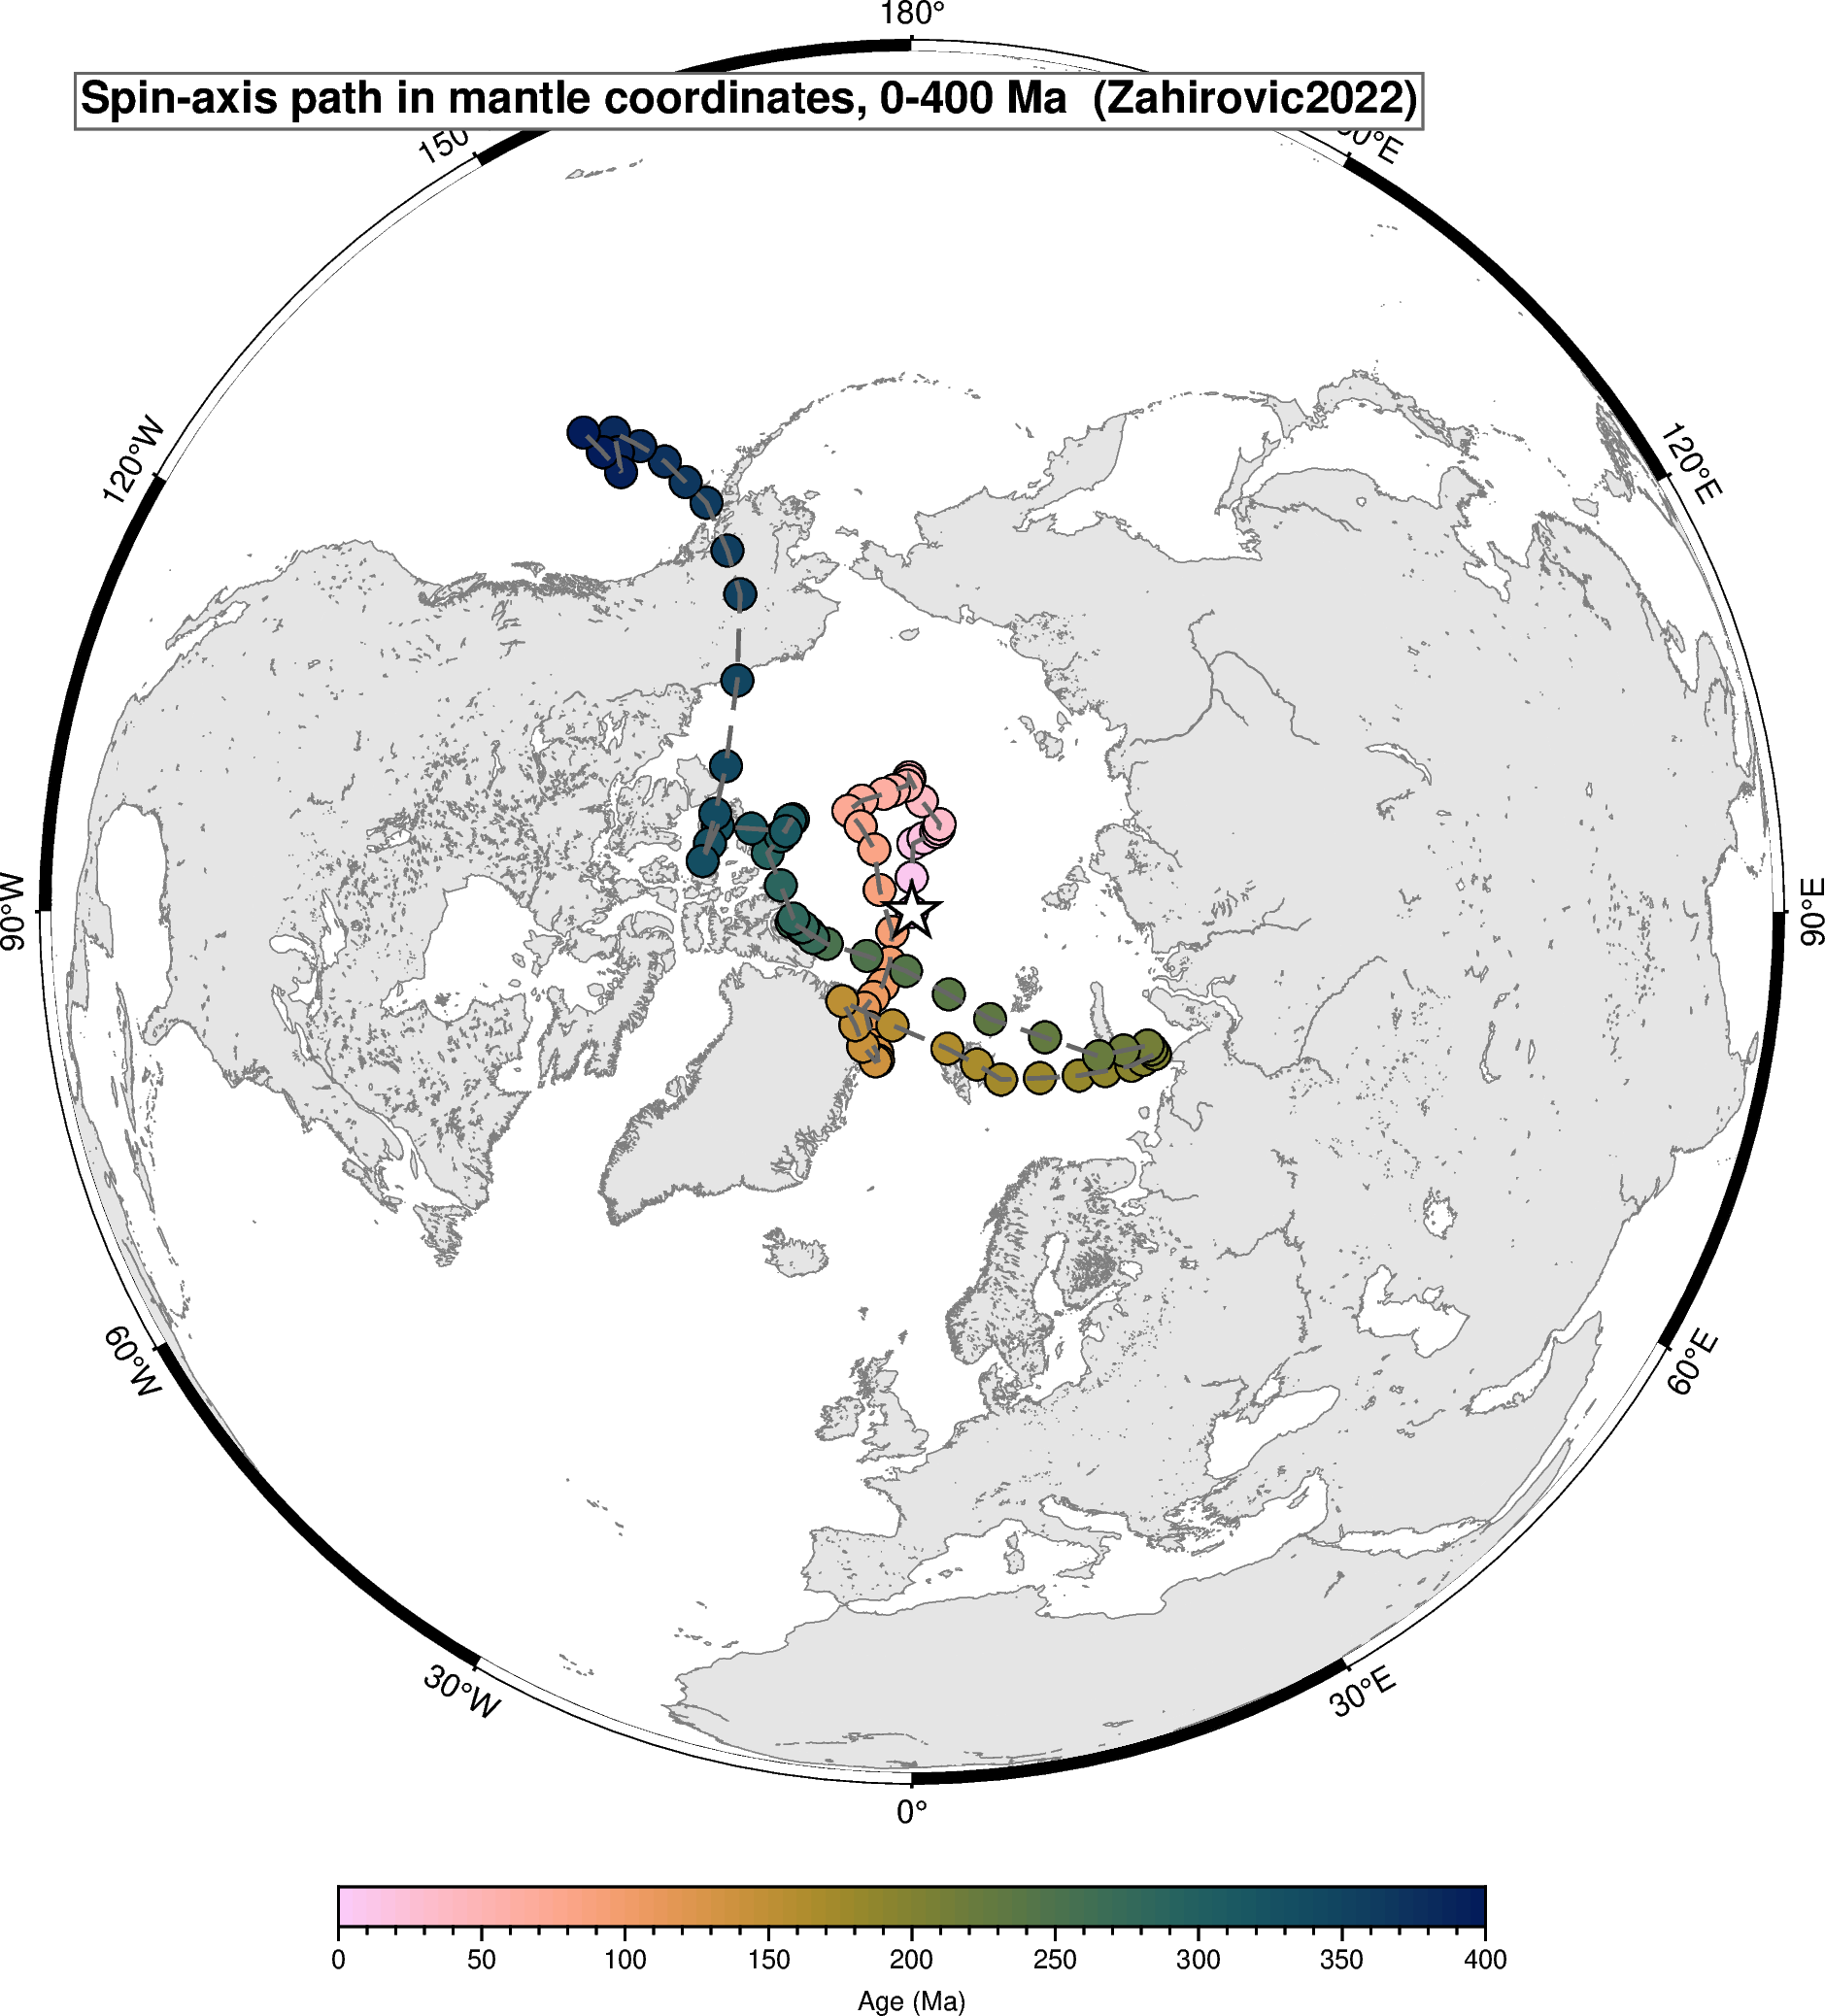

In [6]:
plot_df = tpw_df.copy()      # pole at 0 Ma sits at 90°N, the centre of the map

fig = pygmt.Figure()
fig.basemap(region=POLE_PATH_REGION, projection=POLE_PATH_PROJ, frame="ag")
fig.coast(region=POLE_PATH_REGION, projection=POLE_PATH_PROJ,
          land="gray90", water="white", shorelines="0.25p,gray50")

pygmt.makecpt(cmap="batlow", series=[0, MAX_AGE_MA, STEP_MA], reverse=True)
fig.plot(x=plot_df["pole_lon"], y=plot_df["pole_lat"],
         style="c0.28c", fill=plot_df["age_ma"], cmap=True, pen="0.4p,black",
         region=POLE_PATH_REGION, projection=POLE_PATH_PROJ)

# Track line connecting successive poles
fig.plot(x=plot_df["pole_lon"], y=plot_df["pole_lat"],
         pen="1.0p,gray40,-", region=POLE_PATH_REGION, projection=POLE_PATH_PROJ)

fig.colorbar(position="JBC+w10c/0.35c+h+o0/1c",
             frame=["a50f10", "x+lAge (Ma)"])
fig.plot(x=[0], y=[90], style="a0.5c", fill="white", pen="0.8p,black",
         region=POLE_PATH_REGION, projection=POLE_PATH_PROJ)        # present-day pole
fig.text(text=f"Spin-axis path in mantle coordinates, 0-{MAX_AGE_MA:.0f} Ma  ({MODEL_NAME})",
         position="TL", offset="0.25c/-0.25c", justify="TL",
         font="11p,Helvetica-Bold,black", fill="white", pen="0.6p,gray40")
fig.show(width=900)


### How to read the TPW path

- Each dot is the position of the spin axis in mantle coordinates at one age (colour = age). The star is the present-day pole at 0 Ma.
- **The distance of a dot from the star** is the accumulated TPW at that age. **A path that moves directly away from the star** means TPW in one direction; **a path that returns** means TPW reversed.
- **The direction in which the path leaves the star** gives the equatorial axis of the TPW rotation: the axis is 90° away from that direction (columns `axis_lon` of the table).
- Because the starting point is the pole itself, the path shows TPW as a latitude change only. A rotation about the spin axis (longitude) is not constrained by paleomagnetism and is not part of the path.


## 6. TPW rate through time, bar chart

Incremental TPW rate in ° per Myr, one bar per 5-Myr interval. All bars are ≥ 0 by construction (see §4). No published curve is overplotted; see *Extend this* for how to add one from the original source.


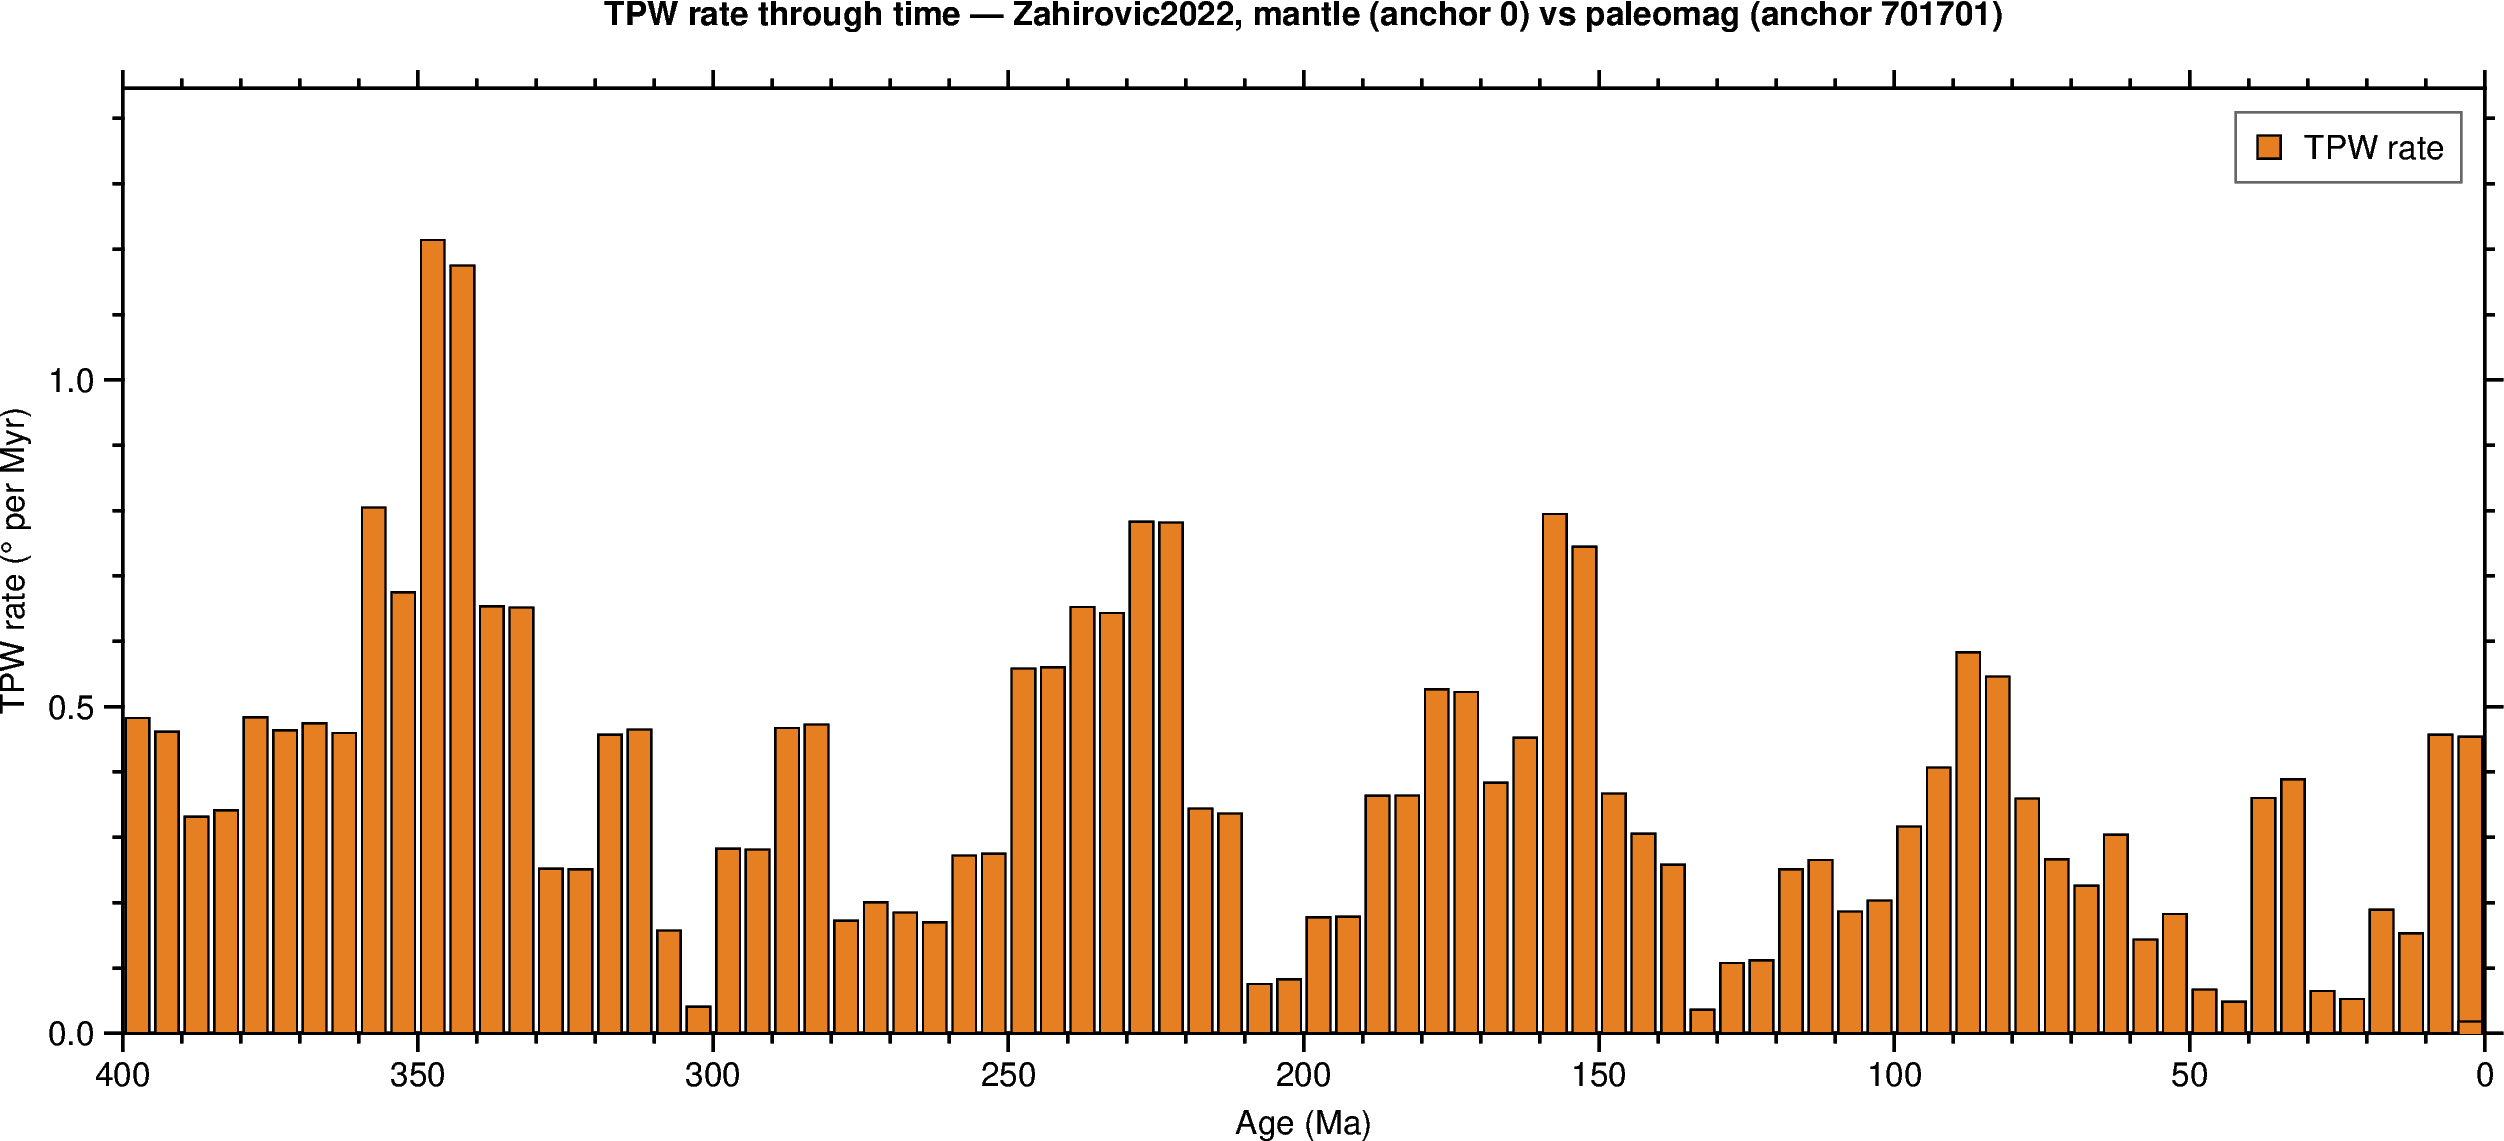

In [7]:
fig = pygmt.Figure()
Y_MAX = float(incr_df["rate_deg_per_myr"].max()) * 1.15 + 0.05
fig.basemap(region=[0, MAX_AGE_MA, 0, Y_MAX], projection="X-20c/8c",
            frame=["WSne+t" + f"TPW rate through time — {MODEL_NAME}, mantle (anchor {ANCHOR_MANTLE_FRAME}) vs paleomag (anchor {ANCHOR_PALEOMAG_FRAME})",
                   "xa50f10+lAge (Ma)",
                   "yaf+lTPW rate (° per Myr)"])

# Bars drawn as explicit polygons in data coordinates so their width is
# RATE_BAR_WIDTH_MA Ma whatever the projection scale.
_hw = RATE_BAR_WIDTH_MA / 2.0
for _xc, _yc in zip(incr_df["age_mid_ma"], incr_df["rate_deg_per_myr"]):
    if _yc <= 0: continue
    fig.plot(x=[_xc - _hw, _xc + _hw, _xc + _hw, _xc - _hw, _xc - _hw],
             y=[0, 0, _yc, _yc, 0],
             fill="#e67e22", pen="0.4p,black")
# One phantom plot for the legend entry
fig.plot(x=[incr_df["age_mid_ma"].iloc[0]], y=[0], style="s0.28c",
         fill="#e67e22", pen="0.4p,black",
         label=f"TPW rate, {MODEL_NAME} built-in paleomag frame (701701)")
fig.legend(position="JTR+jTR+o0.2c/0.2c", box="+gwhite+p0.5p,gray40")
fig.show(width=1100)


### How to read the rate plot

- **Bars**: TPW rate for each 5-Myr interval, in ° per Myr (great-circle distance of the spin-axis path divided by the time step).
- **Single tall bars** are often noise in the rotation poles of the model rather than real rapid TPW. Rates that stay elevated over several consecutive intervals are more meaningful.
- **The mean rate** printed above is a *path-length* mean. It is an upper bound on the net TPW rate, because back-and-forth jitter adds path length without net displacement. The net displacement is printed as well.

**Caveats**

- The 701701 paleomagnetic frame is Z22's own construction, not an independent paleomagnetic reconstruction. The result is "TPW implied by the two frames of this model", not a direct measurement.
- Only one plate (Africa) is used. In theory the result is the same for any plate. Differences between plates point to inconsistencies in the rotation chain.
- Comparing the curve with published TPW estimates is left as an exercise (see *Extend this*). Published estimates differ considerably in amplitude and timing, so decide first which one is the right benchmark for the question.


## 7. TPW from the T33 GPMDB paleomagnetic frame (anchor 701702)

Z22's built-in `701701` anchor (used above) is one construction of a paleomagnetic frame, but not the only one. **T33** rebuilds a paleomagnetic frame directly from the Global Paleomagnetic Database (Pisarevsky et al. 2022) and embeds it as a *new* synthetic anchor plate `701702` in an augmented rotation file, `data/Zahirovic2022_with_gpmdb_frame.rot`. That gives a second, independent paleomagnetic construction. If T33 has been run and its output is on disk, the same TPW path and rates can be computed for 701702 and compared with 701701. If the file does not exist, this section prints a message and is skipped.


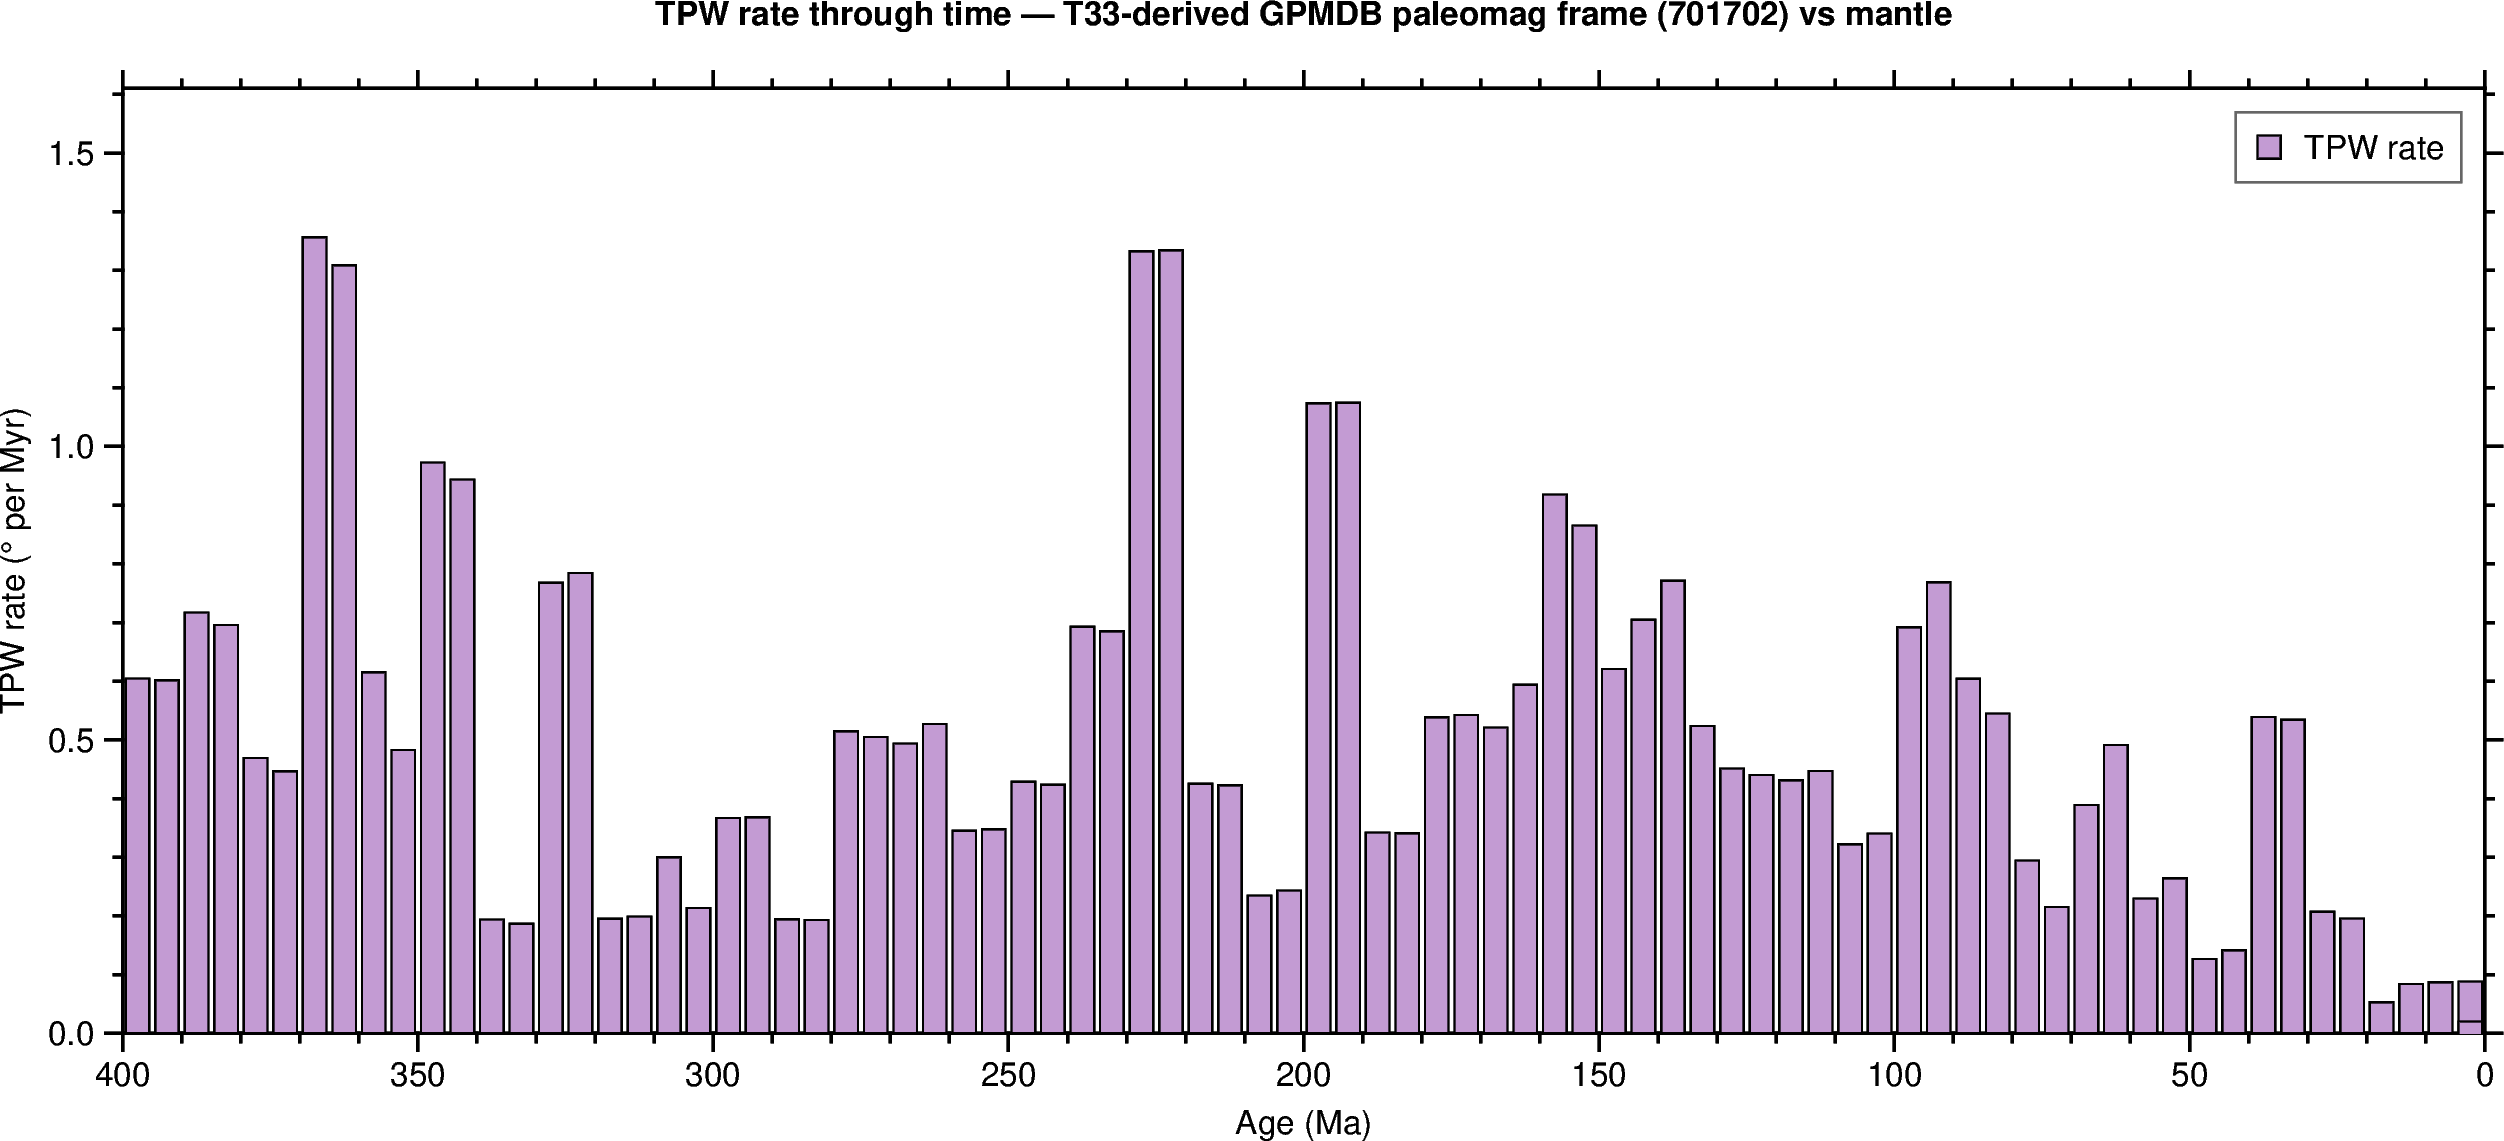

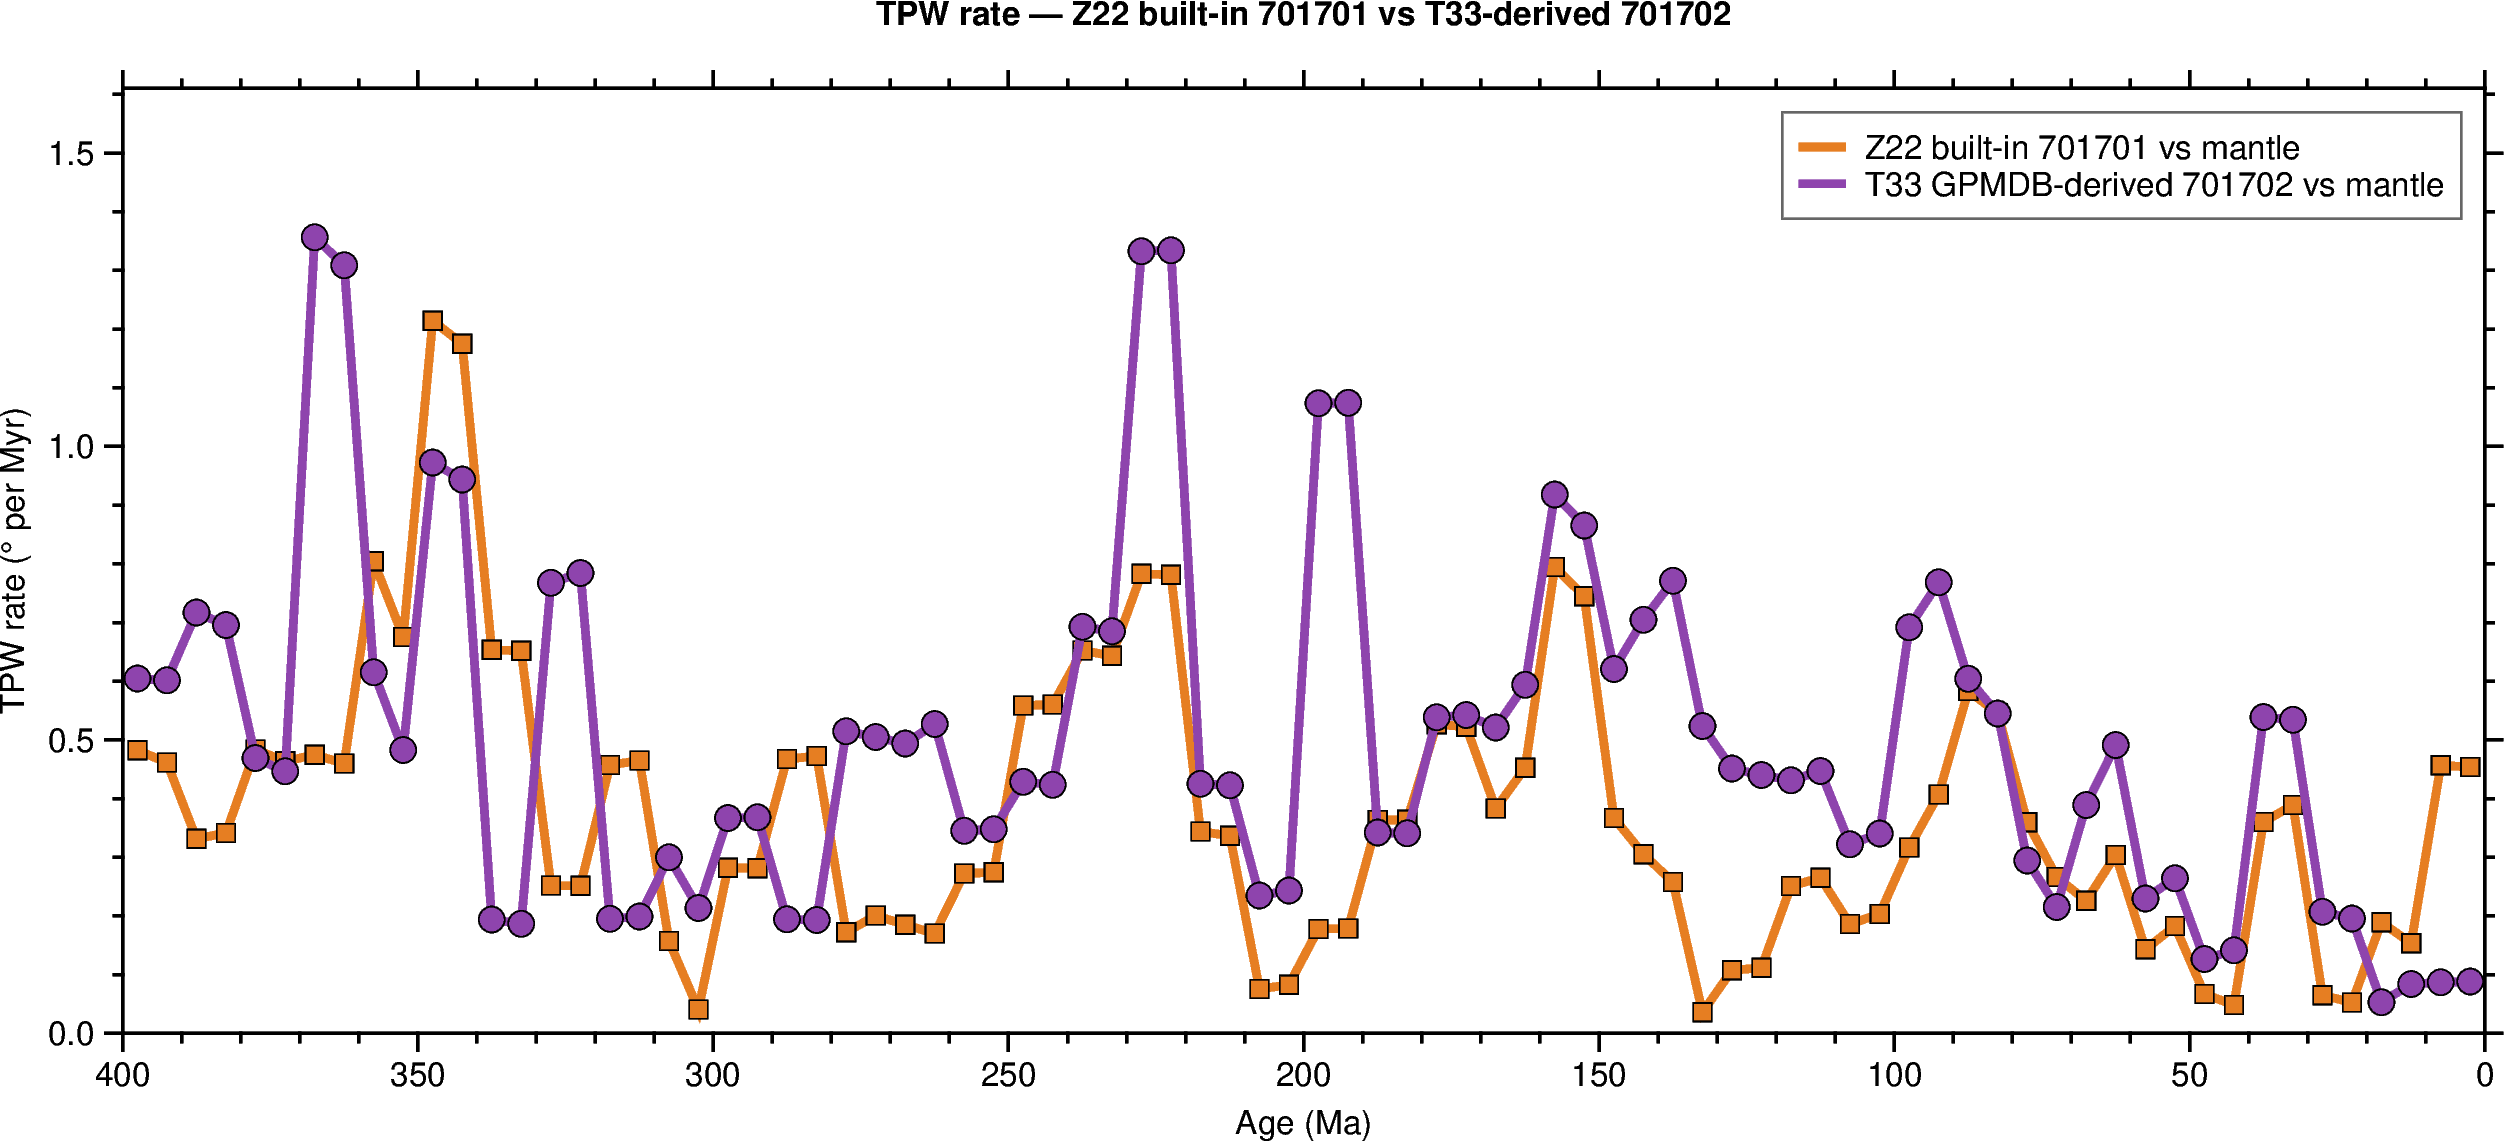

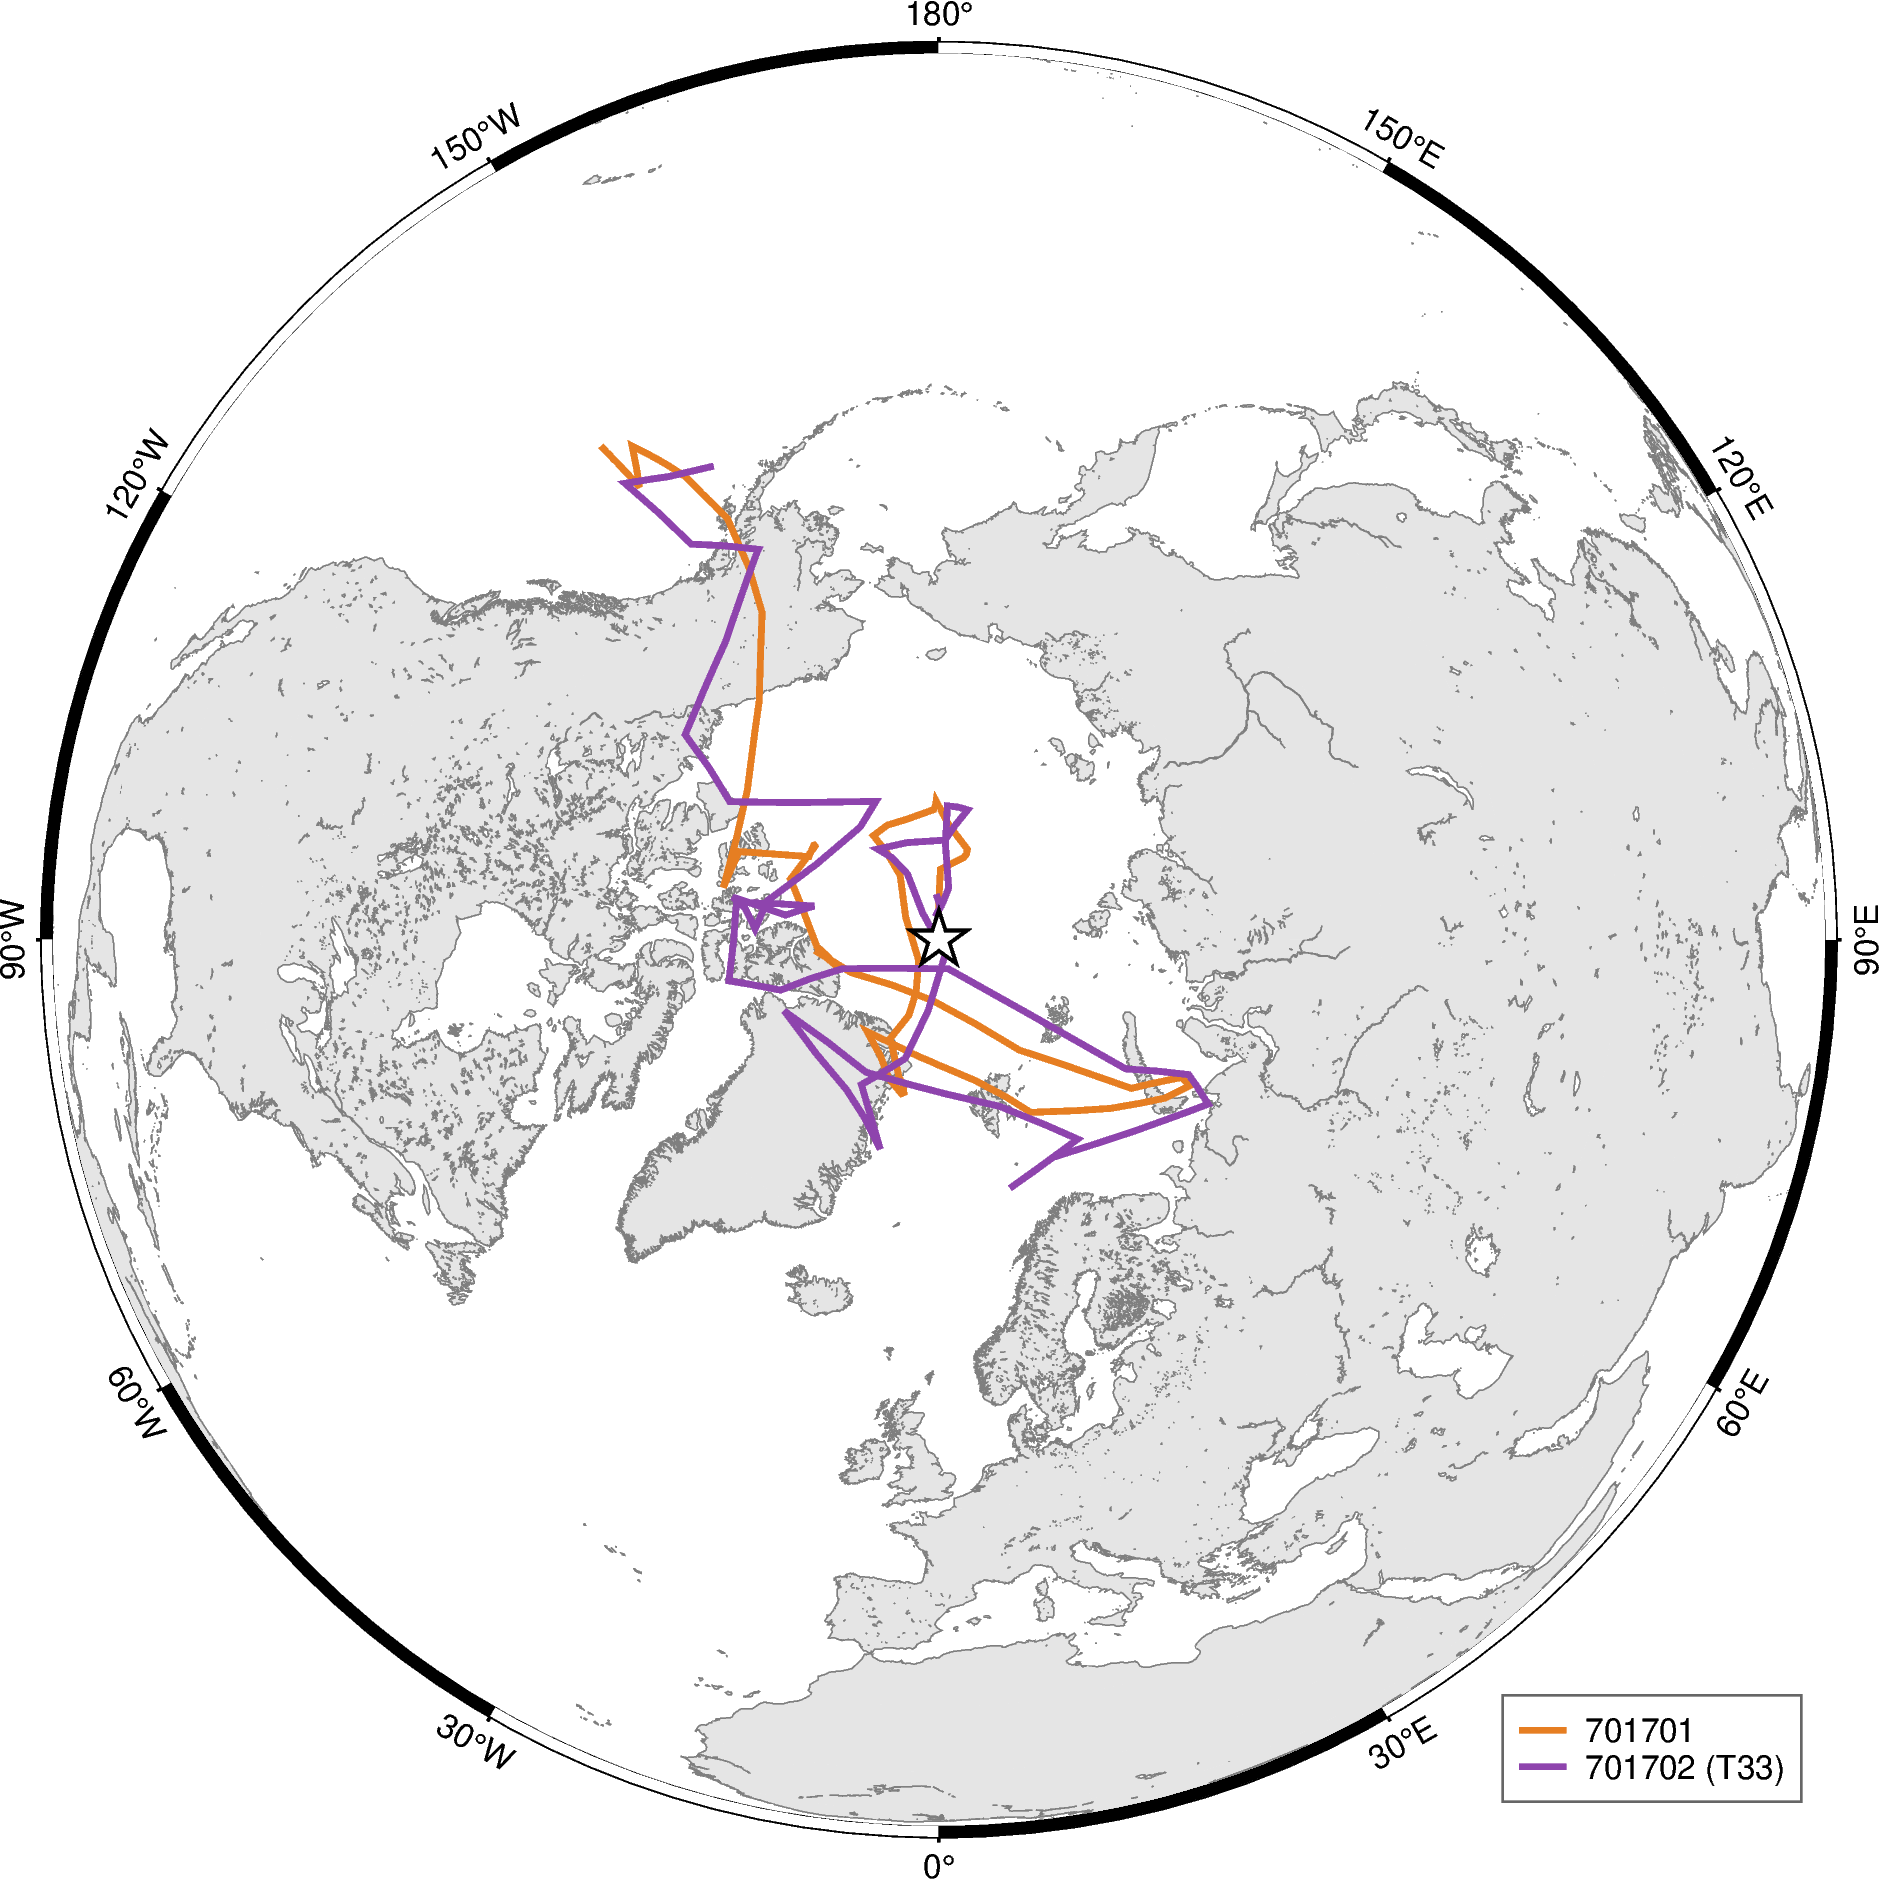

  Z22 built-in 701701: mean 0.376 °/Myr, peak 1.214 °/Myr at ~348 Ma, net displacement at 400 Ma 42.5°
  T33-derived 701702 : mean 0.507 °/Myr, peak 1.357 °/Myr at ~368 Ma, net displacement at 400 Ma 36.3°


In [8]:
AUG_ROT_PATH = Path("data/Zahirovic2022_with_gpmdb_frame.rot")

if not AUG_ROT_PATH.exists():
    print("  [!] data/Zahirovic2022_with_gpmdb_frame.rot not found.")
    print("      Run T33 (Paleomagnetic Reference Frame) first to build it,")
    print("      then re-run this cell for the second TPW comparison.")
else:
    # Load the T33-derived augmented rotation model with anchor 701702
    rot_model_aug = pygplates.RotationModel(str(AUG_ROT_PATH))
    ANCHOR_GPMDB_FRAME = 701702        # T33 synthetic anchor

    tpw_df_gpmdb  = tpw_path(rot_model_aug, PLATE_ID_MANTLE_FRAME, ANCHOR_MANTLE_FRAME,
                             ANCHOR_GPMDB_FRAME, AGES)
    incr_df_gpmdb = tpw_increments(tpw_df_gpmdb)

    # === PLOT 1: bar chart, same structure as section 6 ===
    fig = pygmt.Figure()
    Y_MAX = float(incr_df_gpmdb["rate_deg_per_myr"].max()) * 1.15 + 0.05
    fig.basemap(region=[0, MAX_AGE_MA, 0, Y_MAX], projection="X-20c/8c",
                frame=["WSne+t" + "TPW rate through time — T33-derived GPMDB paleomag frame (701702) vs mantle",
                       "xa50f10+lAge (Ma)",
                       "yaf+lTPW rate (° per Myr)"])
    _hw = RATE_BAR_WIDTH_MA / 2.0
    for _xc, _yc in zip(incr_df_gpmdb["age_mid_ma"], incr_df_gpmdb["rate_deg_per_myr"]):
        if _yc <= 0: continue
        fig.plot(x=[_xc - _hw, _xc + _hw, _xc + _hw, _xc - _hw, _xc - _hw],
                 y=[0, 0, _yc, _yc, 0],
                 fill="#c39bd3", pen="0.4p,black")
    fig.plot(x=[incr_df_gpmdb["age_mid_ma"].iloc[0]], y=[0], style="s0.28c",
             fill="#c39bd3", pen="0.4p,black",
             label=f"TPW rate, T33 GPMDB paleomag frame (701702)")
    fig.legend(position="JTR+jTR+o0.2c/0.2c", box="+gwhite+p0.5p,gray40")
    fig.show(width=1100)

    # === PLOT 2: overlay of the two paleomagnetic-frame TPW curves ===
    Y_MAX2 = max(float(incr_df["rate_deg_per_myr"].max()),
                 float(incr_df_gpmdb["rate_deg_per_myr"].max())) * 1.15 + 0.05
    fig = pygmt.Figure()
    fig.basemap(region=[0, MAX_AGE_MA, 0, Y_MAX2], projection="X-20c/8c",
                frame=["WSne+tTPW rate — Z22 built-in 701701 vs T33-derived 701702",
                       "xa50f10+lAge (Ma)",
                       "yaf+lTPW rate (° per Myr)"])
    fig.plot(x=incr_df["age_mid_ma"], y=incr_df["rate_deg_per_myr"],
             pen="2p,#e67e22", label="Z22 built-in 701701 vs mantle")
    fig.plot(x=incr_df["age_mid_ma"], y=incr_df["rate_deg_per_myr"],
             style="s0.22c", fill="#e67e22", pen="0.3p,black")
    fig.plot(x=incr_df_gpmdb["age_mid_ma"], y=incr_df_gpmdb["rate_deg_per_myr"],
             pen="2p,#8e44ad", label="T33 GPMDB-derived 701702 vs mantle")
    fig.plot(x=incr_df_gpmdb["age_mid_ma"], y=incr_df_gpmdb["rate_deg_per_myr"],
             style="c0.22c", fill="#8e44ad", pen="0.3p,black")
    fig.legend(position="JTR+jTR+o0.2c/0.2c", box="+gwhite+p0.5p,gray40")
    fig.show(width=1100)

    # === PLOT 3: the two TPW paths (spin axis in mantle coordinates) ===
    fig = pygmt.Figure()
    fig.basemap(region=POLE_PATH_REGION, projection=POLE_PATH_PROJ, frame="ag")
    fig.coast(region=POLE_PATH_REGION, projection=POLE_PATH_PROJ,
              land="gray90", water="white", shorelines="0.25p,gray50")
    fig.plot(x=tpw_df["pole_lon"], y=tpw_df["pole_lat"], pen="1.5p,#e67e22",
             region=POLE_PATH_REGION, projection=POLE_PATH_PROJ, label="701701")
    fig.plot(x=tpw_df_gpmdb["pole_lon"], y=tpw_df_gpmdb["pole_lat"], pen="1.5p,#8e44ad",
             region=POLE_PATH_REGION, projection=POLE_PATH_PROJ, label="701702 (T33)")
    fig.plot(x=[0], y=[90], style="a0.5c", fill="white", pen="0.8p,black",
             region=POLE_PATH_REGION, projection=POLE_PATH_PROJ)
    fig.legend(position="JBR+jBR+o0.2c/0.2c", box="+gwhite+p0.5p,gray40")
    fig.show(width=700)

    # Summary numbers side-by-side
    for _lab, _df, _tp in (("Z22 built-in 701701", incr_df, tpw_df),
                           ("T33-derived 701702 ", incr_df_gpmdb, tpw_df_gpmdb)):
        _i = _df["rate_deg_per_myr"].idxmax()
        print(f"  {_lab}: mean {_df['rate_deg_per_myr'].mean():.3f} °/Myr, "
              f"peak {_df.loc[_i,'rate_deg_per_myr']:.3f} °/Myr at ~{_df.loc[_i,'age_mid_ma']:.0f} Ma, "
              f"net displacement at {AGES[-1]:.0f} Ma {_tp['tpw_angle_deg'].iloc[-1]:.1f}°")


### How to read the comparison

**Plot 1** repeats §6 with the T33-derived paleomagnetic frame (anchor 701702). **Plot 2** overlays the two rate curves. **Plot 3** overlays the two paths of the spin axis in mantle coordinates.

- **Where the curves and paths agree**, the TPW implied by the model's mantle frame is robust against the construction of the paleomagnetic frame.
- **Where they diverge**, the result depends on how the paleomagnetic frame was built (for example where pole density is low). Check the pole coverage of that interval in T33.
- Differences that remain when two paleomagnetic frames agree point to the mantle side of the decomposition (the model's mantle frame) rather than to the paleomagnetic side.

This separates the paleomagnetic-frame uncertainty from the mantle-frame uncertainty in the TPW estimate, as far as two frames allow.


## Extend this

- **Vary the plate.** Swap `PLATE_ID_MANTLE_FRAME` / `PLATE_ID_PALEOMAG_FRAME` to Australia (801), Antarctica (802) or Eurasia (301). The spin-axis path should be identical (up to numerical noise) because TPW is a global rotation. Any large disagreement signals a problem in the frame chain.
- **Benchmark against a published TPW estimate.** Take the TPW path or rates from the original publication of your choice (for example Steinberger & Torsvik 2008, Doubrovine et al. 2012, or Vaes & van Hinsbergen 2025), add them as a second series on the plots in §5 and §6, and compare timing and amplitude. Published estimates differ, so state which one you use and why.
- **Another model.** Merdith 2021 and Cao 2024 reach further back in time. Their default frames differ from Z22's, so decide first which of the available anchors is the mantle frame and which the paleomagnetic frame (see T02).
- **Plot TPW-corrected vs uncorrected continent positions.** For a chosen age, plot Africa in both frames as coloured polygons; the visual gap between them is the accumulated TPW rotation (plus the unconstrained longitude shift).
- **Cross-reference with T68.** The TPW between two ages helps to explain the climate differences that T68 finds between reference frames.

## Related notebooks

- **T35**: paleo-mantle reference-frame uncertainty on continent positions. T41 explains the origin of that uncertainty.
- **T68**: reference-frame uncertainty on reconstructed paleoclimate.
- **T33–T34**: paleomagnetic reference-frame construction (T33 builds the 701702 anchor used in §7).

## Sources

- Vaes, B. & van Hinsbergen, D.J.J. (2025). Slow true polar wander around varying equatorial axes since 320 Ma. *AGU Advances* 6(2), e2024AV001515. https://doi.org/10.1029/2024AV001515
- Steinberger, B. & Torsvik, T.H. (2008). Absolute plate motions and true polar wander in the absence of hotspot tracks. *Nature* 452, 620–623. https://doi.org/10.1038/nature06824
- Doubrovine, P.V., Steinberger, B. & Torsvik, T.H. (2012). Absolute plate motions in a reference frame defined by moving hot spots in the Pacific, Atlantic, and Indian oceans. *Journal of Geophysical Research: Solid Earth* 117, B09101. https://doi.org/10.1029/2011JB009072
- Torsvik, T.H. & Cocks, L.R.M. (2016). *Earth History and Palaeogeography*. Cambridge University Press. https://doi.org/10.1017/9781316225523
- Zahirovic, S., Eleish, A., Doss, S., Pall, J., Cannon, J., Pistone, M., Tetley, M.G., Young, A. & Fox, P. (2022). Subduction and carbonate platform interactions. *Geoscience Data Journal* 9(2), 371–383. https://doi.org/10.1002/gdj3.146
- Pisarevsky, S.A., Li, Z.X., Tetley, M.G., Liu, Y. & Beardmore, J.P. (2022). An updated internet-based Global Paleomagnetic Database. *Earth-Sci. Rev.* 235, 104258. https://doi.org/10.1016/j.earscirev.2022.104258
